# A zoo of PSFs at the lantern input

What the lantern sees: for a range of pupil aberrations, the pupil OPD, the
focal-plane intensity and phase of the field that reaches the lantern's input
face, and the lantern's output.

| group | configurations |
|---|---|
| **flat** | the unaberrated PSF |
| **single piston** | one petal at increasing piston, from 50 nm to a whole wavelength |
| **twin pairs** | configurations and their twins (see `piston2.ipynb`), including point-symmetric ones whose twin is their sign flip |
| **low order** | tip, tilt, focus (both signs), astigmatism: no piston |
| **SCAO-like residuals** | small random residuals across all 10 modes, at the levels below |

All at 800 nm, the wavelength of the single-wavelength models (Part A of
`workbench.ipynb`). The output is the power of each of the 19 channels as a
fraction of the incident light, so it includes the input coupling.

**Modal basis** (`ANDES_400pix_all_modes.fits`):

- Modes 0-4 move one petal each, so their coefficient is that petal's
  piston in nm; petal 6 is the reference.
- Modes 5-9 are smooth unit-RMS modes, so their coefficient is in nm RMS:
  tip, tilt, focus, astigmatism at 45 degrees and astigmatism at 0 degrees.

**SCAO-like residual levels.** The ANDES SCAO end-to-end simulations give a
Strehl ratio of 77% at 1614 nm for an I = 8 guide star, 72% at I = 12, 60% at
I = 14 and 45% at I = 15, in median seeing at 30 degrees zenith (Selmi et
al., *ANDES, the high-resolution spectrograph for ELT: the AO system*,
AO4ELT8, Table 1; marked preliminary, without NCPA). By the Maréchal
approximation 77% at 1614 nm is about 131 nm RMS of total residual. That
total is spread over some 4000 corrected modes, and no per-mode breakdown is
given, so the share in these 10 low-order modes is smaller. The zoo uses
25 nm, 50 nm (assumptions, of the order of the petal residuals quoted for
good phasing) and 131 nm (the whole budget in these modes, a pessimistic
bound) of total RMS over the 10 modes. Change `psfzoo.RESIDUAL_LEVELS_NM` to
use others.

The lantern outputs come from `scripts/psf_zoo.py` (one cbeam propagation of
all configurations); the PSFs are computed here.

**Reading the plots.** Each row shows:

1. the pupil OPD;
2. the focal-plane intensity (log, relative to the flat PSF's peak);
3. the complex focal-plane field;
4. the lantern's 19 channel powers.

The field is drawn with "domain colouring": hue for the phase, brightness
for the intensity over its top 4 decades. So the phase is shown wherever
there is light. Dark rings and phase singularities (optical vortices: points
around which every hue appears) fade to black instead of being masked out.

In [1]:
import os
os.environ["CBEAM_BACKEND"] = "numpy"

import numpy as np
import ml_reconstruct as ml
from ml_reconstruct import psfzoo
from ml_reconstruct.psfzoo import plot_zoo, pair_table, random_pair_scale, strehl, pupil_opd
from ml_reconstruct.piston2 import focal_fields
from ml_reconstruct.simulate import bp

Detected IPython. Loading juliacall extension. See https://juliapy.github.io/PythonCall.jl/stable/compat/#IPython


In [2]:
zoo = np.load("data/ml/psf_zoo/channels_800nm.npz")       # scripts/psf_zoo.py
names, groups, C, S = list(zoo["names"]), zoo["groups"], zoo["coeff"], zoo["signals"]
p800 = bp.get_simulation_parameters(3, 0.8)
ifunc = bp.load_ifunc(p800["ifunc_file"]); bp.center_ifunc_mask(ifunc)
E, ext = focal_fields(ifunc, p800, C)
opd = pupil_opd(ifunc, C)
E_flat = E[names.index("flat wavefront")]
scale = random_pair_scale(ml.LanternDataset.load("data/ml/spectral_41wl.npz").signals[:, 20])   # 800 nm
show = lambda g, **kw: plot_zoo([n for n in names if groups[names.index(n)] == g],
                                opd[groups == g], E[groups == g], ext, S[groups == g], E_flat, **kw)
print(f"{len(names)} configurations; output distances below are in units of {scale:.4f}, the median "
      f"distance between two random configurations of the +-5 um dataset at 800 nm")

30 configurations; output distances below are in units of 0.1068, the median distance between two random configurations of the +-5 um dataset at 800 nm


## 1. The unaberrated PSF

The diffraction pattern of the 6-petal pupil, with its central obstruction
and spiders. Its core falls well inside the lantern's 9 um input (dashed),
and the lantern takes in 43% of the light. The rest falls outside the input
face or does not couple into its 20 guided modes. The central core gets the
largest share.

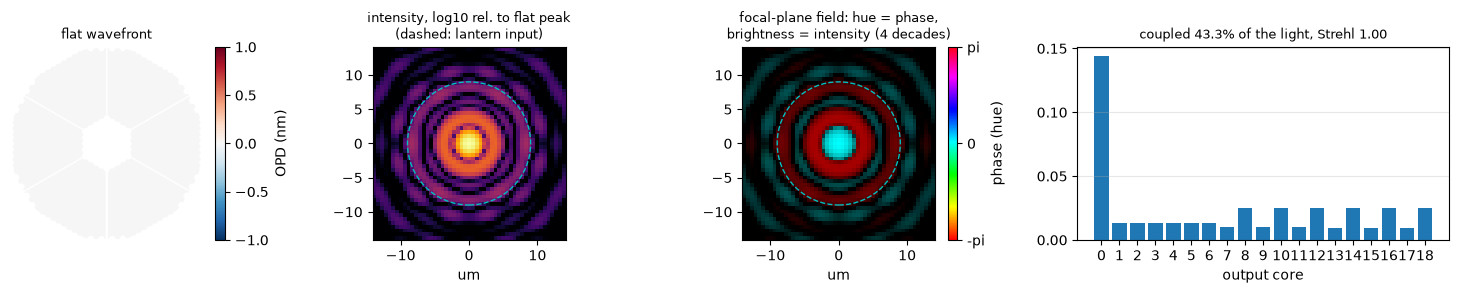

In [3]:
show("flat")

## 2. One petal pistoned

Petal 0 at increasing piston. The pupil phase is 2 pi p / lambda, so the PSF
is periodic in the piston with the period lambda = 800 nm: 800 nm gives back
the flat PSF, and 600 nm is the same as -200 nm. At 400 nm (lambda/2) the
petal is in antiphase: the central peak splits in two, the Strehl ratio is
0.45, and the coupled fraction is lowest (39%). The lantern's response moves
from the central core into a few first- and second-ring cores.

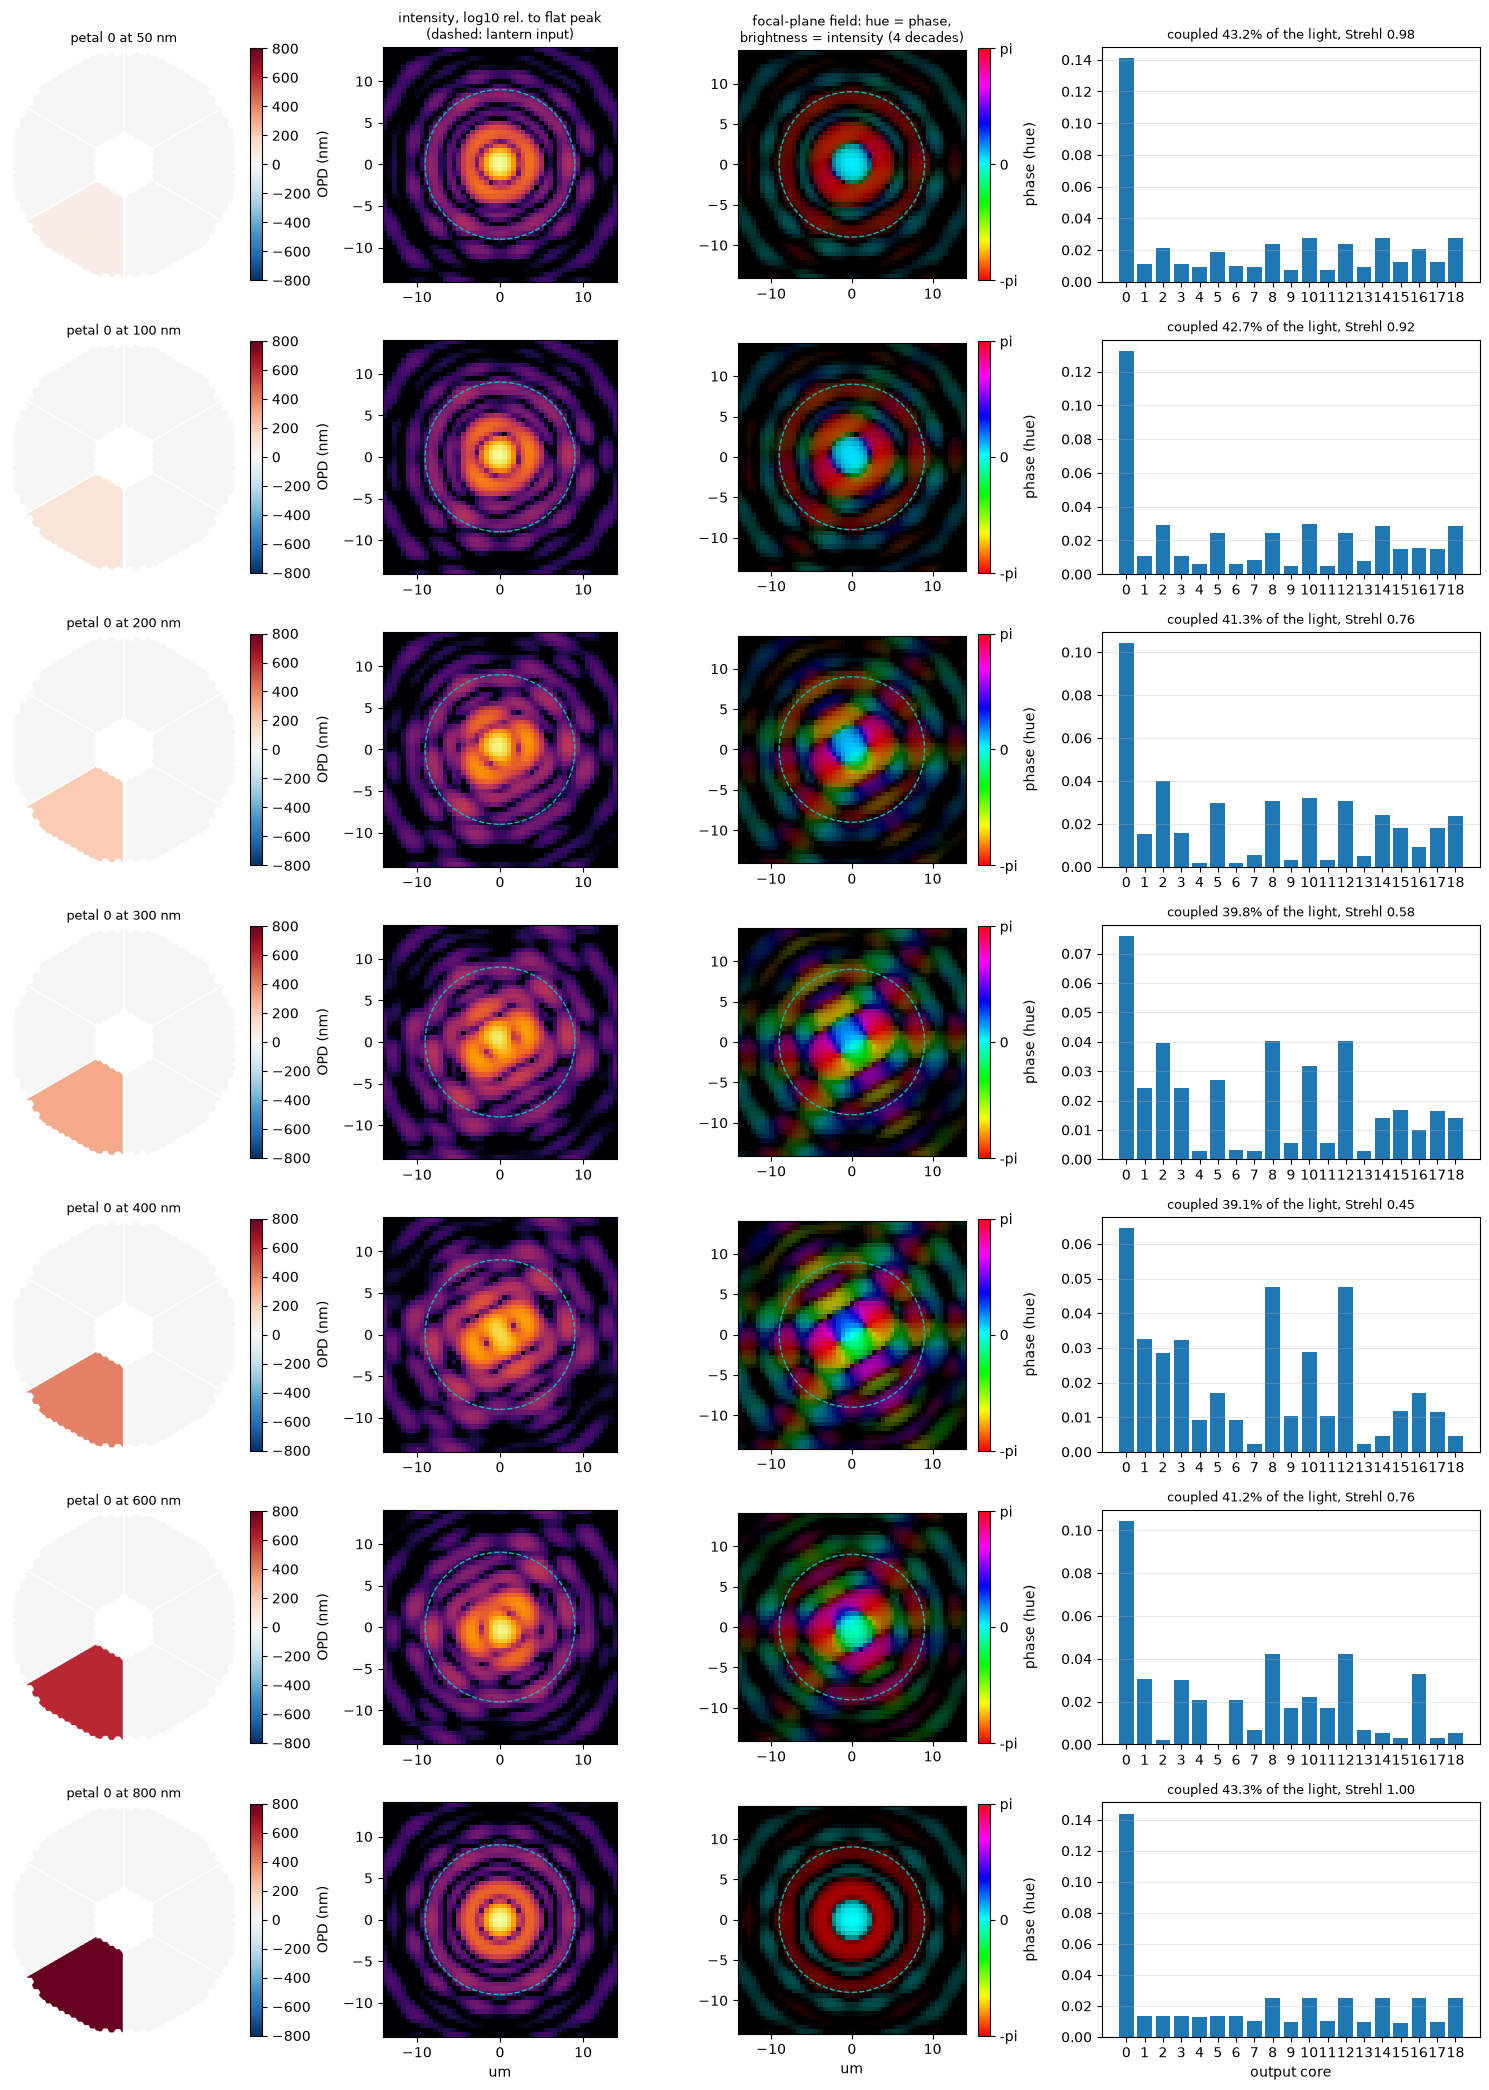

In [4]:
show("single piston")

In [5]:
pairs = [("petal 0 at 800 nm", "flat wavefront"), ("petal 0 at 50 nm", "flat wavefront"),
         ("petal 0 at 200 nm", "petal 0 at 600 nm")]
display(pair_table(names, E, S, pairs, scale).round(3))

,a,b,intensity_diff,conj_phase_rad,output_distance
0,petal 0 at 800 nm,flat wavefront,0.000,0.021,0.000
1,petal 0 at 50 nm,flat wavefront,0.083,0.126,0.139
2,petal 0 at 200 nm,petal 0 at 600 nm,0.490,0.661,0.718


## 3. Twin pairs

The twin -phi(-x) of a pupil phase has the same focal-plane intensity and the
complex-conjugate phase. The lantern can only tell them apart through its
modal phases (`piston2.ipynb`). The pairs shown:

- **typical:** a validation configuration whose twin the lantern separates
  well;
- **critical:** a nearly point-symmetric configuration it confuses with its
  twin;
- **point-symmetric:** opposite petals equal, whose twin is exactly its sign
  flip -p.

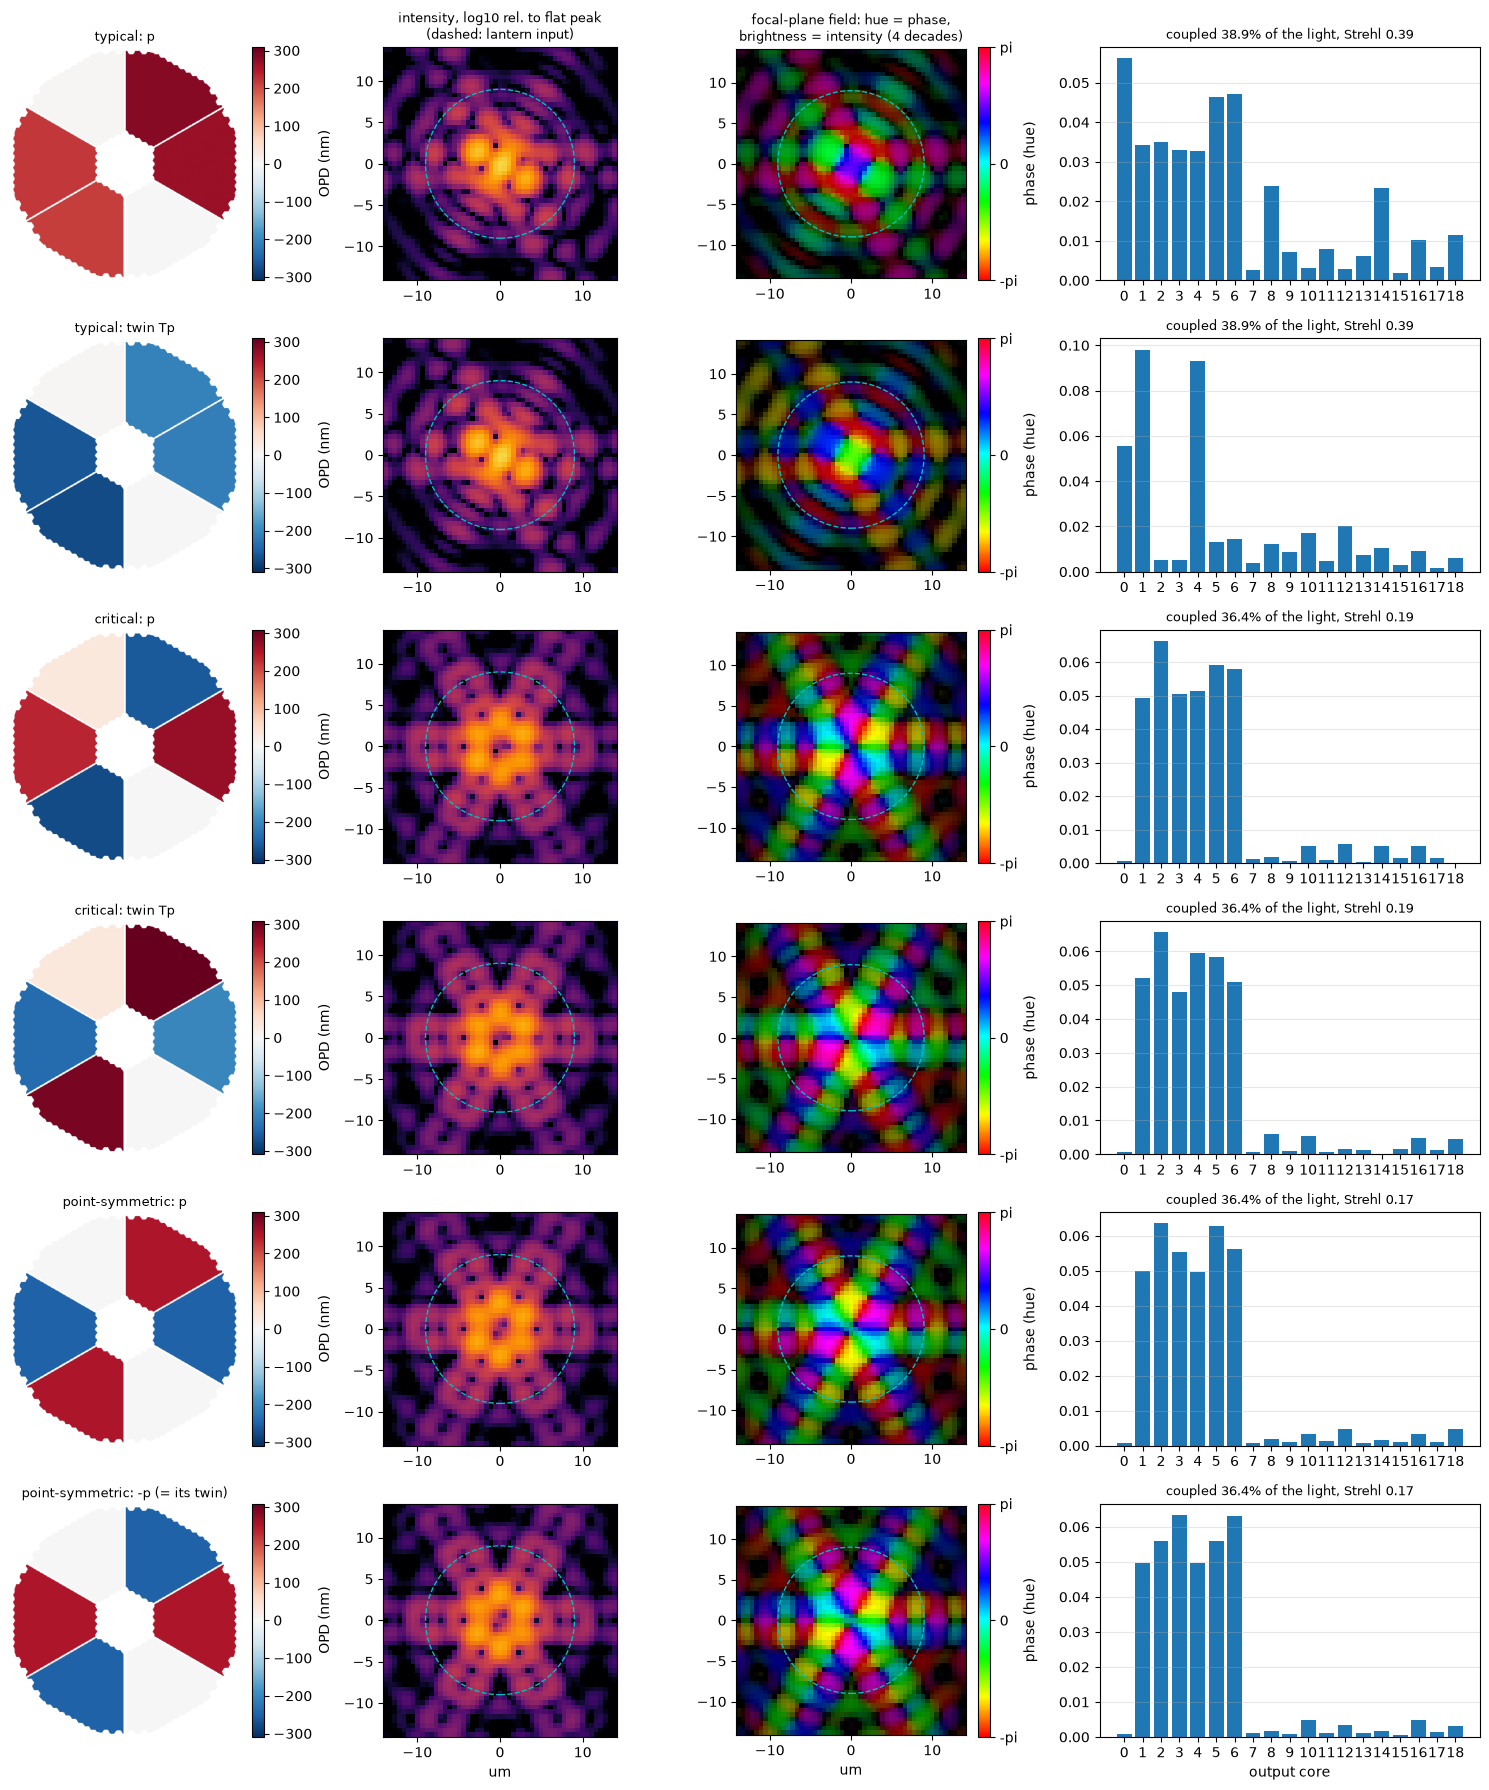

In [6]:
show("twin pairs")

In [7]:
pairs = [("typical: p", "typical: twin Tp"), ("critical: p", "critical: twin Tp"),
         ("point-symmetric: p", "point-symmetric: -p (= its twin)")]
display(pair_table(names, E, S, pairs, scale).round(3))

,a,b,intensity_diff,conj_phase_rad,output_distance
0,typical: p,typical: twin Tp,0.011,0.044,1.042
1,critical: p,critical: twin Tp,0.018,0.257,0.134
2,point-symmetric: p,point-symmetric: -p (= its twin),0.020,0.028,0.141


All three twins have the same intensity, to the pupil mask's residual
asymmetry, and the conjugate phase. The lantern separates the typical one
almost as well as two unrelated configurations, but the point-symmetric
configurations hardly at all. Their PSFs have a dark centre, and the light
goes almost equally into the six first-ring cores.

## 4. Low-order aberrations, no piston

- **Tip and tilt** move the PSF across the input face and cost coupling
  (43% -> 37% for 100 nm RMS). Their "Strehl 1.00" is not a mistake: a
  pure tilt shifts the peak without lowering it.
- **Astigmatism** stretches it.
- **Focus** spreads it symmetrically. Focus is even, phi(-x) = phi(x), so
  its twin is its own sign flip: +100 nm and -100 nm of focus give exactly
  the same PSF intensity. This is the classic sign ambiguity of focal-plane
  imaging. The lantern, however, sees the phase.

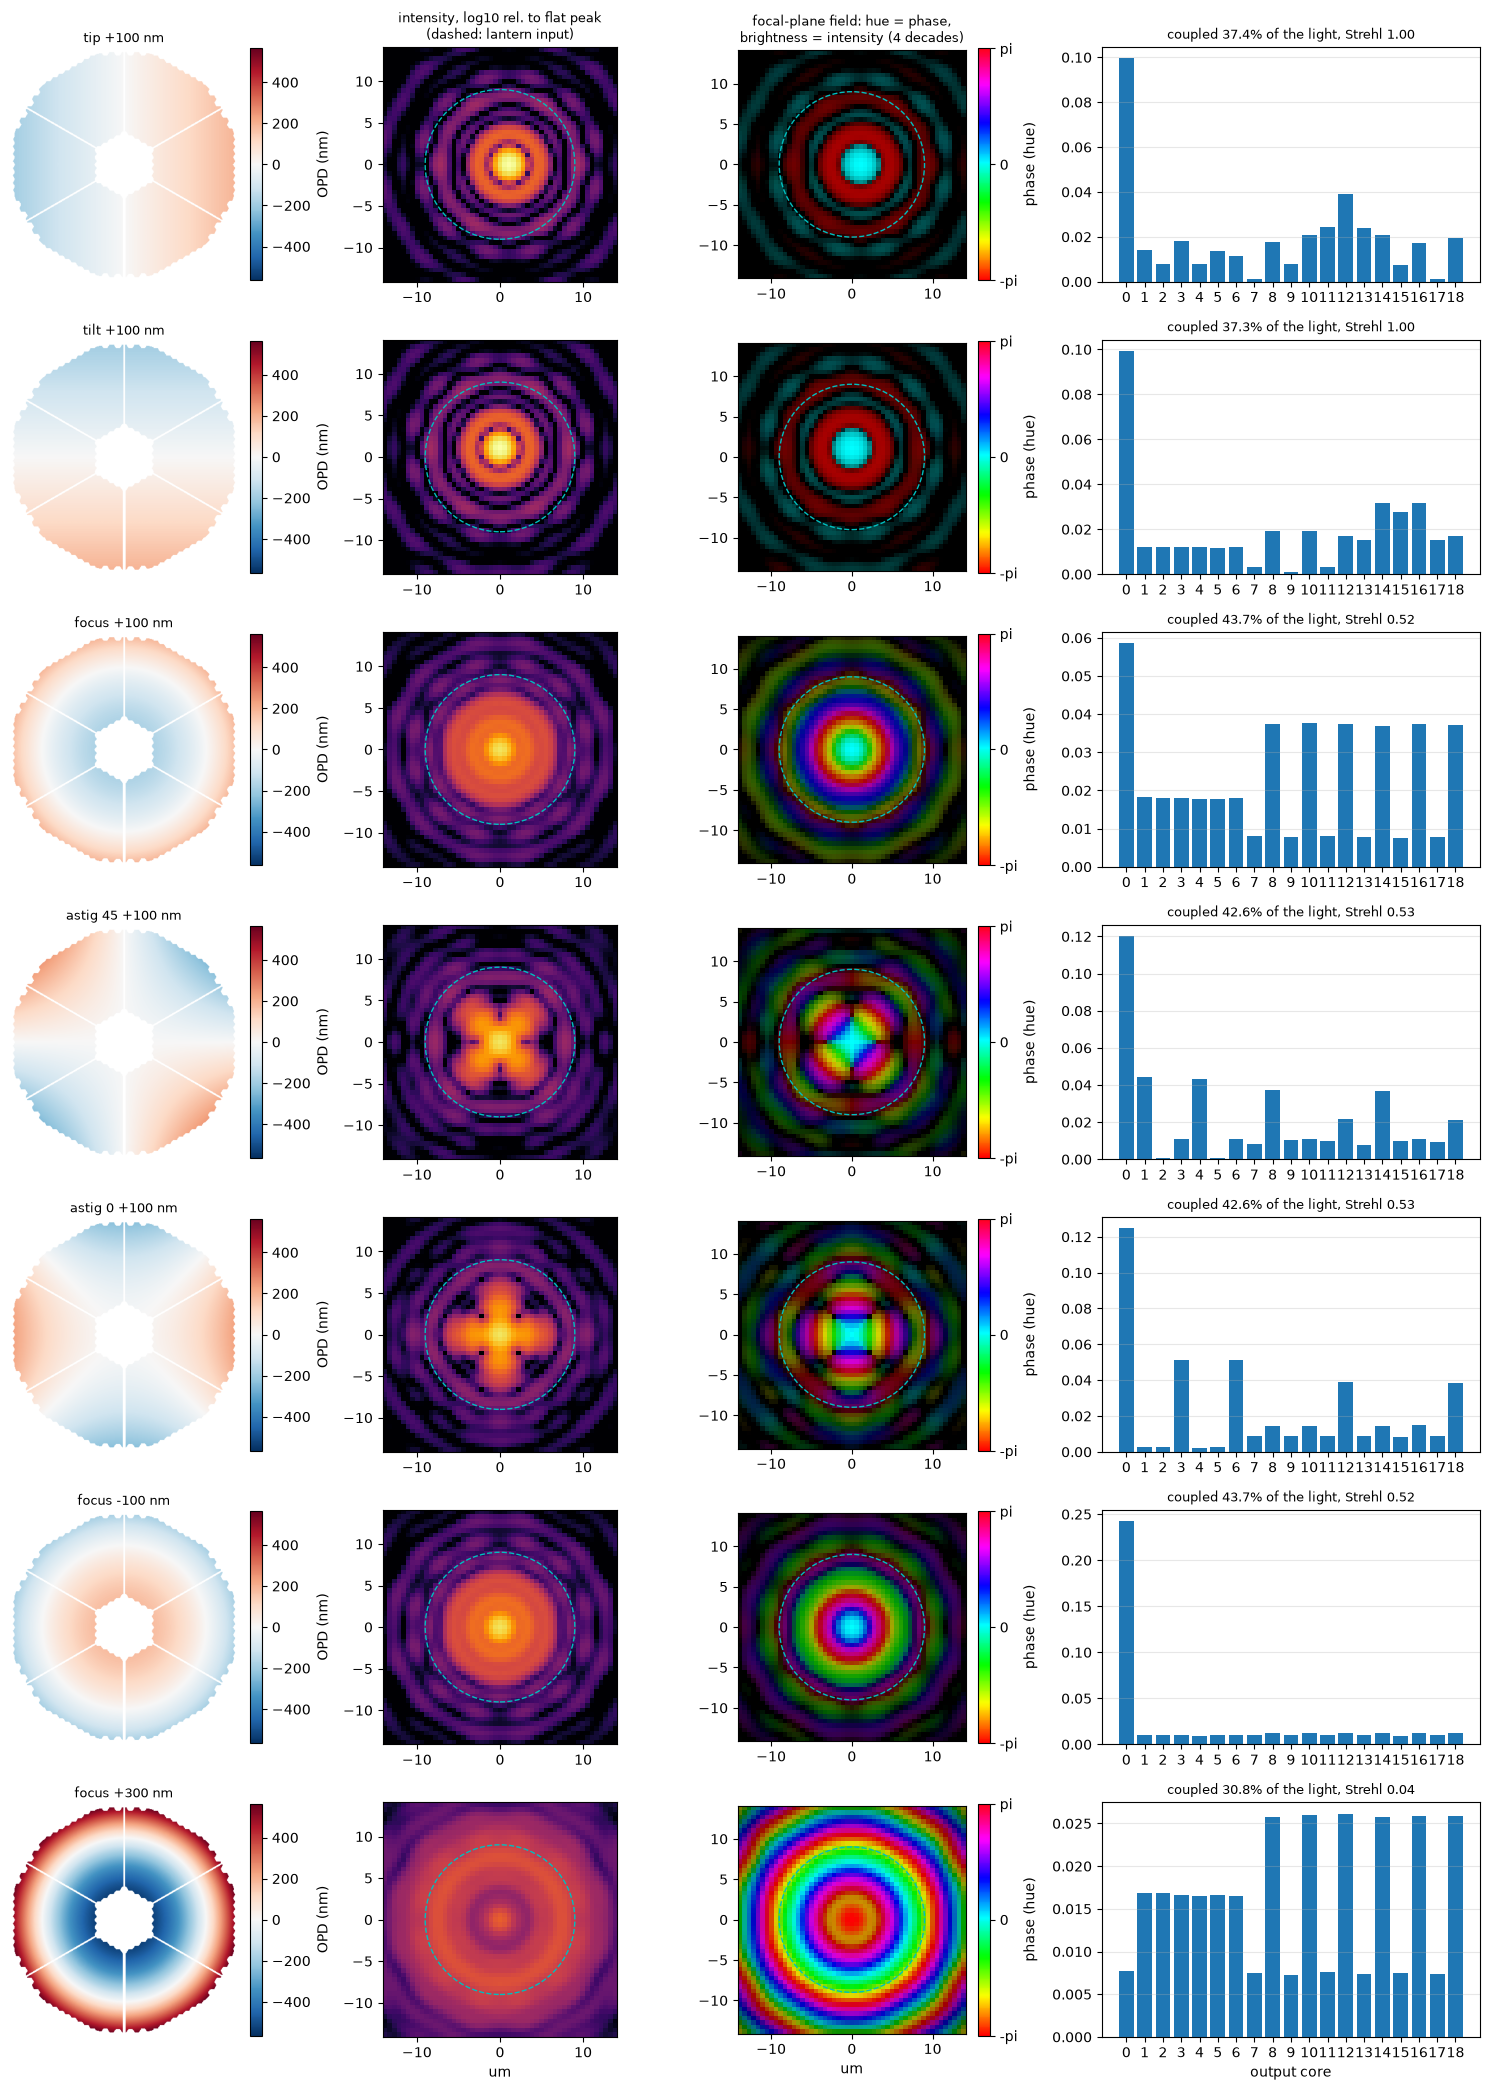

In [8]:
show("low order")

In [9]:
display(pair_table(names, E, S, [("focus +100 nm", "focus -100 nm"), ("tip +100 nm", "tilt +100 nm"),
                                 ("astig 45 +100 nm", "astig 0 +100 nm")], scale).round(3))

,a,b,intensity_diff,conj_phase_rad,output_distance
0,focus +100 nm,focus -100 nm,0.003,0.022,1.825
1,tip +100 nm,tilt +100 nm,0.784,0.043,0.424
2,astig 45 +100 nm,astig 0 +100 nm,0.230,1.331,0.852


Focus +-100 nm couples the same light (43.7%) but distributes it very
differently: the central core gets about a quarter of it at -100 nm and only
6% at +100 nm. That is a large output distance for the same PSF intensity, so
the lantern resolves the focus sign that a camera on the PSF cannot. Its
modal phases break the twin well for this even, smooth aberration, unlike
for the point-symmetric petal configurations of section 3.

## 5. SCAO-like residuals

Random residuals across all 10 modes (pistons and low order), scaled to a
total RMS over the pupil of 25, 50 and 131 nm (see the top of the notebook
for where these come from). The Strehl ratio here is at 800 nm, so it is much
lower than in H band for the same residual. The table compares it with the
Maréchal estimate exp(-(2 pi sigma / lambda)^2), and gives the 1614 nm
equivalent and the distance of the lantern output from the flat one.

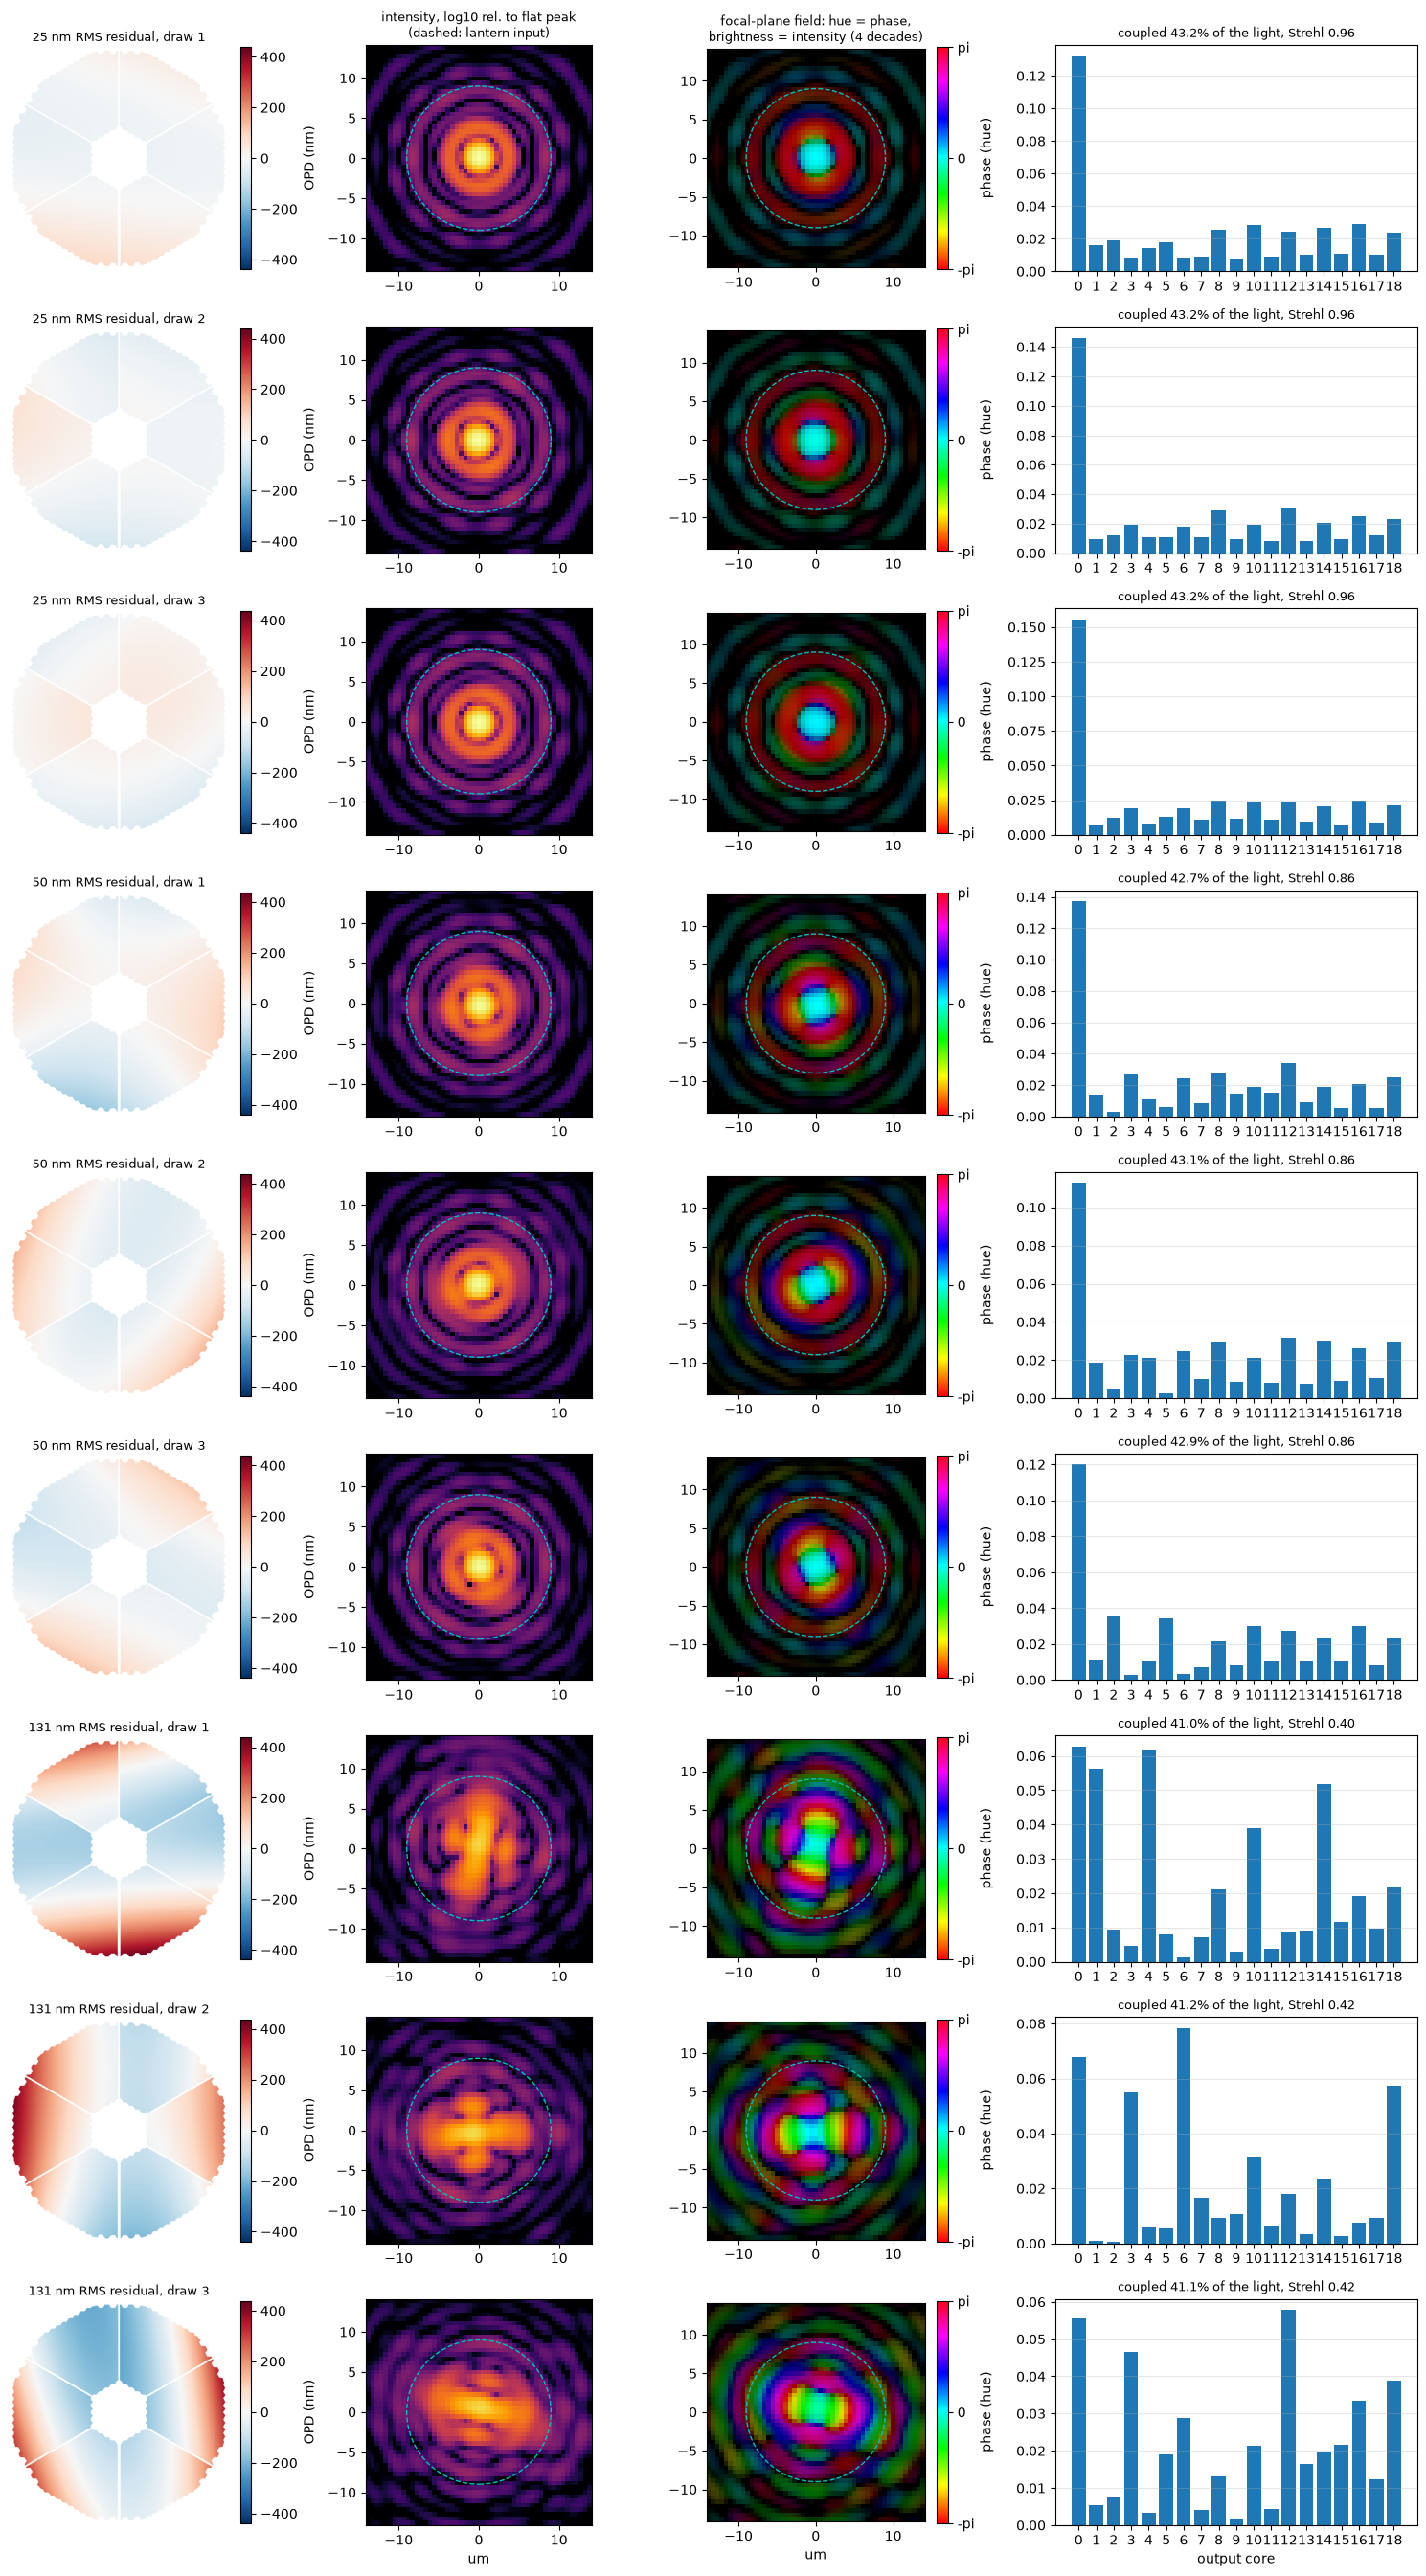

In [10]:
show("SCAO-like residuals")

In [11]:
g = groups == "SCAO-like residuals"
sig = np.array([psfzoo.pupil_rms(ifunc, c) for c in C[g]])
sr800 = strehl(E[g], E_flat)
d_flat = np.linalg.norm(S[g] - S[names.index("flat wavefront")], axis=1) / scale
for n, s, r, d in zip(np.array(names)[g], sig, sr800, d_flat):
    print(f"  {n:34s} {s:6.1f} nm RMS   Strehl at 800 nm {r:.2f} (Marechal {np.exp(-(2 * np.pi * s / 800) ** 2):.2f})"
          f"   Marechal at 1614 nm {np.exp(-(2 * np.pi * s / 1614) ** 2):.2f}   output distance to flat {d:.2f}")

  25 nm RMS residual, draw 1           25.0 nm RMS   Strehl at 800 nm 0.96 (Marechal 0.96)   Marechal at 1614 nm 0.99   output distance to flat 0.16
  25 nm RMS residual, draw 2           25.0 nm RMS   Strehl at 800 nm 0.96 (Marechal 0.96)   Marechal at 1614 nm 0.99   output distance to flat 0.14
  25 nm RMS residual, draw 3           25.0 nm RMS   Strehl at 800 nm 0.96 (Marechal 0.96)   Marechal at 1614 nm 0.99   output distance to flat 0.17
  50 nm RMS residual, draw 1           50.0 nm RMS   Strehl at 800 nm 0.86 (Marechal 0.86)   Marechal at 1614 nm 0.96   output distance to flat 0.26
  50 nm RMS residual, draw 2           50.0 nm RMS   Strehl at 800 nm 0.86 (Marechal 0.86)   Marechal at 1614 nm 0.96   output distance to flat 0.37
  50 nm RMS residual, draw 3           50.0 nm RMS   Strehl at 800 nm 0.86 (Marechal 0.86)   Marechal at 1614 nm 0.96   output distance to flat 0.40
  131 nm RMS residual, draw 1         131.0 nm RMS   Strehl at 800 nm 0.40 (Marechal 0.35)   Marechal at 1

## 6. Summary

- **One petal pistoned.** The PSF changes periodically with the piston,
  with period lambda. Up to about lambda/4 the change is small and smooth;
  at lambda/2 the petal is in antiphase and the central peak is weakest.
  This periodicity is why a single wavelength only sees pistons modulo
  lambda.
- **Twins.** Every configuration has a twin with the same PSF intensity.
  The lantern tells most twins apart through its modal phases, even the sign
  of focus, but not the nearly point-symmetric petal configurations. Their
  PSFs have a dark centre and feed the six first-ring cores almost equally.
  This is the cause of the rare large errors and of piston 2's advantage in
  `piston2.ipynb`.
- **Low-order aberrations.** Tip and tilt mostly cost coupling. Focus and
  astigmatism mostly redistribute the light among the cores.
- **SCAO-like residuals.** At 25 and 50 nm RMS in these modes the PSF stays
  close to the flat one: Strehl 0.96 and 0.86 at 800 nm, as the Maréchal
  approximation predicts. The lantern output still moves measurably, by
  0.14-0.17 and 0.26-0.40 of a random pair's distance. That is as much as
  a 50 nm piston of one petal (0.14) or more, so these residuals are within
  reach of a reconstructor working after the SCAO loop. The 131 nm bound
  (the whole ANDES budget in these 10 modes) distorts the PSF strongly at
  800 nm (Strehl 0.4) and moves the output about as far as an unrelated
  configuration (0.99-1.11).